# Horizonte de 1 día y validación en ventanas

Dos preguntas sobre el modelo de `02_modelo.ipynb` (versión 1):

1. **Horizonte.** La versión 1 solo usa información de 7 días o más atrás (predice con una semana de anticipación).
   Para el restock basta con predecir el día siguiente. ¿Cuánto mejora si el modelo también ve lo que pasó **ayer**
   (`lag_1d`, `nivel_ayer`)?
2. **Estabilidad.** La prueba original (28 jul – 31 ago) es un solo periodo, y es atípico (vacaciones y lluvias).
   ¿El resultado se sostiene en otros periodos? Se evalúa en **3 ventanas de 35 días**; cada una entrena con todo
   lo anterior. La última ventana es la partición original.

Todos los XGBoost usan los hiperparámetros de la versión 1; el número de árboles se elige por early stopping
en cada ventana, con validación dentro de su propio train.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modelo as M

In [2]:
validos = M.cargar_validos()
estaciones = M.cargar_estaciones()
tabla = M.construir_tabla(validos, estaciones)
tabla = M.agregar_calendario(tabla)
tabla = M.agregar_clima(tabla, M.descargar_clima("2026-03-01", "2026-08-31"))
tabla = M.agregar_rezagos_1d(tabla)
print(f"Filas: {len(tabla):,} | sin lag_1d: {tabla['lag_1d'].isna().mean():.1%}")

h = pd.read_csv("../data/processed/busqueda_hiperparametros.csv").iloc[0]
params = {k: (h[k] if k == "objective" else int(h[k]) if k in ("max_depth", "min_child_weight") else float(h[k]))
          for k in M.ESPACIO_BUSQUEDA}
print("Hiperparámetros (versión 1):", params)

Filas: 2,842,368 | sin lag_1d: 0.6%
Hiperparámetros (versión 1): {'learning_rate': 0.1, 'max_depth': 8, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'objective': 'count:poisson'}


## Entrenamiento y evaluación en las 3 ventanas

In [3]:
variantes = {
    "XGBoost v1 (7 días)": M.FEATURES,
    "XGBoost v2 (7 días + calendario + clima)": M.FEATURES_V2,
    "XGBoost 1 día": M.FEATURES_1D,
}

filas, preds_ultima = [], {}
for i, (train, test, ini, fin) in enumerate(M.ventanas_por_fechas(tabla, n=3, dias=35), start=1):
    ventana = f"{i}: {ini:%d %b} – {fin:%d %b}"
    y = test[M.TARGET].to_numpy()
    preds = {
        "Promedio histórico": M.baseline_promedio(train, test),
        "Media 4 semanas": M.baseline_media_4sem(test),
        "Ayer (misma hora)": test["lag_1d"].fillna(test["media_4sem"]).to_numpy(dtype=float),
    }
    for nombre, feats in variantes.items():
        n_arb = M.elegir_arboles(train, params, feats)
        modelo = M.entrenar_xgb(train, params, n_arb, feats)
        preds[nombre] = np.clip(modelo.predict(test[feats]), 0, None)
    for nombre, p in preds.items():
        filas.append({"ventana": ventana, "modelo": nombre, **M.metricas(y, p)})
    print(ventana, "| " + " | ".join(f"{k}: {M.metricas(y, v)['RMSE']:.3f}" for k, v in preds.items()))
    if i == 3:
        preds_ultima, test_ultima, modelo_1d = preds, test, modelo

res = pd.DataFrame(filas)
res.round(4).to_csv("../data/processed/resultados_ventanas.csv", index=False)

1: 19 May – 22 Jun | Promedio histórico: 2.589 | Media 4 semanas: 2.667 | Ayer (misma hora): 3.714 | XGBoost v1 (7 días): 2.529 | XGBoost v2 (7 días + calendario + clima): 2.548 | XGBoost 1 día: 2.529
2: 23 Jun – 27 Jul | Promedio histórico: 2.591 | Media 4 semanas: 2.652 | Ayer (misma hora): 3.604 | XGBoost v1 (7 días): 2.481 | XGBoost v2 (7 días + calendario + clima): 2.489 | XGBoost 1 día: 2.457
3: 28 Jul – 31 Aug | Promedio histórico: 2.559 | Media 4 semanas: 2.494 | Ayer (misma hora): 3.627 | XGBoost v1 (7 días): 2.370 | XGBoost v2 (7 días + calendario + clima): 2.393 | XGBoost 1 día: 2.354


## Resultados por ventana

In [4]:
for metrica in ["RMSE", "MAE"]:
    t = res.pivot(index="modelo", columns="ventana", values=metrica)
    t["Promedio"] = t.mean(axis=1)
    display(t.sort_values("Promedio").round(3).style.set_caption(metrica))

ventana,1: 19 May – 22 Jun,2: 23 Jun – 27 Jul,3: 28 Jul – 31 Aug,Promedio
modelo,,,,
XGBoost 1 día,2.529000,2.457000,2.354000,2.446000
XGBoost v1 (7 días),2.529000,2.481000,2.370000,2.460000
XGBoost v2 (7 días + calendario + clima),2.548000,2.489000,2.393000,2.477000
Promedio histórico,2.589000,2.591000,2.559000,2.580000
Media 4 semanas,2.667000,2.652000,2.494000,2.604000
Ayer (misma hora),3.714000,3.604000,3.627000,3.648000


ventana,1: 19 May – 22 Jun,2: 23 Jun – 27 Jul,3: 28 Jul – 31 Aug,Promedio
modelo,,,,
XGBoost 1 día,1.485000,1.426000,1.372000,1.428000
XGBoost v2 (7 días + calendario + clima),1.498000,1.433000,1.378000,1.436000
XGBoost v1 (7 días),1.496000,1.444000,1.383000,1.441000
Promedio histórico,1.522000,1.497000,1.448000,1.489000
Media 4 semanas,1.574000,1.529000,1.449000,1.517000
Ayer (misma hora),2.091000,1.994000,1.967000,2.018000


In [5]:
# Mejora de RMSE contra el promedio histórico, por ventana
t = res.pivot(index="modelo", columns="ventana", values="RMSE")
mejora = 1 - t / t.loc["Promedio histórico"]
mejora["Promedio"] = mejora.mean(axis=1)
(mejora.sort_values("Promedio", ascending=False) * 100).round(1)

ventana,1: 19 May – 22 Jun,2: 23 Jun – 27 Jul,3: 28 Jul – 31 Aug,Promedio
modelo,,,,
XGBoost 1 día,2.3,5.2,8.0,5.2
XGBoost v1 (7 días),2.3,4.3,7.4,4.7
XGBoost v2 (7 días + calendario + clima),1.6,4.0,6.5,4.0
Promedio histórico,0.0,0.0,0.0,0.0
Media 4 semanas,-3.0,-2.4,2.6,-0.9
Ayer (misma hora),-43.5,-39.1,-41.7,-41.4


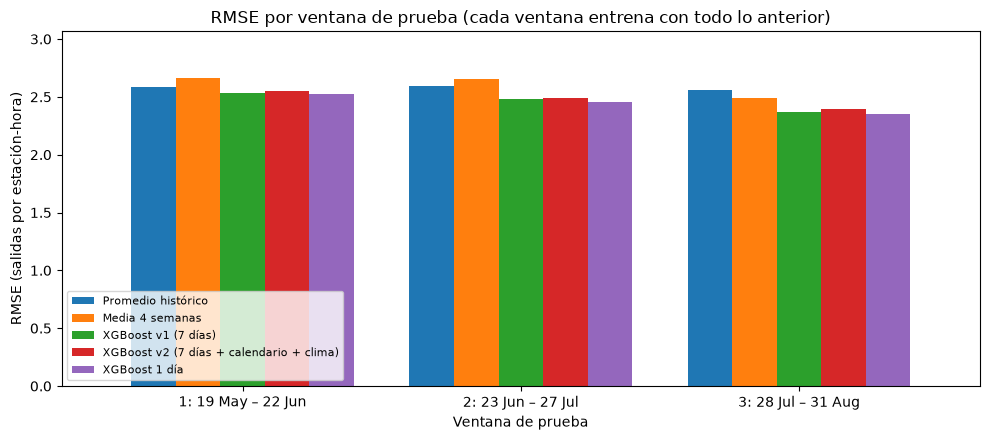

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = ["Promedio histórico", "Media 4 semanas", "XGBoost v1 (7 días)",
         "XGBoost v2 (7 días + calendario + clima)", "XGBoost 1 día"]
t = res.pivot(index="ventana", columns="modelo", values="RMSE")[orden]
t.plot.bar(ax=ax, width=0.8, rot=0)
ax.set_ylabel("RMSE (salidas por estación-hora)")
ax.set_xlabel("Ventana de prueba")
ax.set_title("RMSE por ventana de prueba (cada ventana entrena con todo lo anterior)")
ax.legend(fontsize=8, loc="lower left")
ax.set_ylim(0, t.max().max() * 1.15)
fig.tight_layout()
fig.savefig("../figures/14_rmse_por_ventana.png", dpi=150)
plt.show()

## Última ventana (= partición original): error por hora

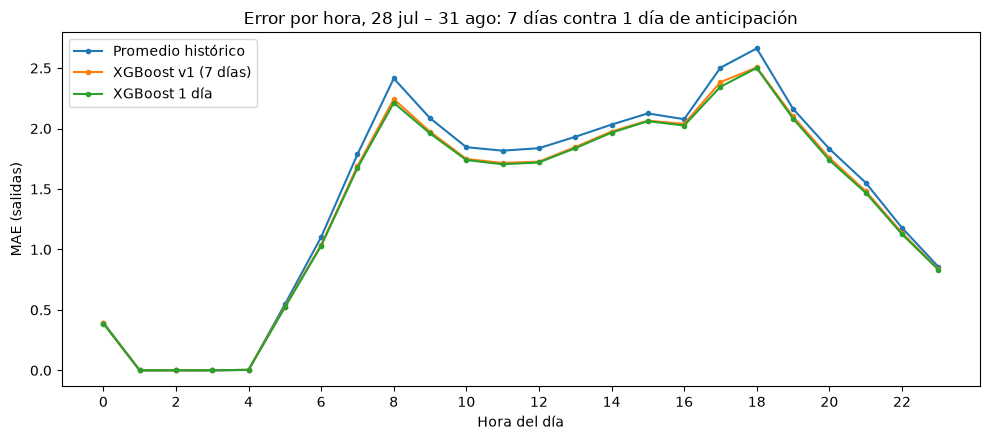

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in ["Promedio histórico", "XGBoost v1 (7 días)", "XGBoost 1 día"]:
    e = M.error_por(test_ultima, preds_ultima[nombre], "hora")
    ax.plot(e.index, e["MAE"], marker="o", ms=3, label=nombre)
ax.set_xlabel("Hora del día")
ax.set_ylabel("MAE (salidas)")
ax.set_title("Error por hora, 28 jul – 31 ago: 7 días contra 1 día de anticipación")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
fig.savefig("../figures/15_error_por_hora_1d.png", dpi=150)
plt.show()

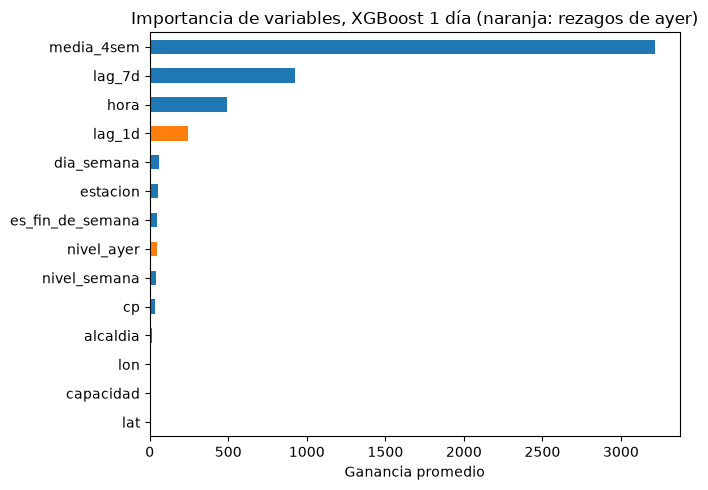

In [8]:
imp = pd.Series(modelo_1d.get_booster().get_score(importance_type="gain")).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color=["C1" if c in M.FEATURES_REZAGO_1D else "C0" for c in imp.index])
ax.set_xlabel("Ganancia promedio")
ax.set_title("Importancia de variables, XGBoost 1 día (naranja: rezagos de ayer)")
fig.tight_layout()
fig.savefig("../figures/16_importancia_variables_1d.png", dpi=150)
plt.show()